# Images Recognition with CNN Transfer Learning


## What to do?

1. Use Chrome Web browser
2. Copy this Notebook to your Google Colab (File -> Save a copy in Drive)

3. Decide two/multiple categories of Images.  For example: Dogs vs. Cats

4. In your google Drive Create two folders: `train` and `test`.  

5. In the train folder create subfolders contains the images for each category.  For example: Folder `dog` (will contain dog images) and folder `cat` (will contain cat images)

6. Use Google Search Image and Imageye to download images of these above categories.  Use **.jpg or .png** images (other types such as .webp and .jfif are skipped). About 25 or more images per category is enough.

[Imageye](https://chrome.google.com/webstore/detail/image-downloader-imageye/agionbommeaifngbhincahgmoflcikhm)


7. Upload the downloaded images to google drive in the associated folders in the train folders (i.e., upload dog images to dogs folder, cat images to cat folder)

8. Upload a few **other** images to the test folder (both dog images and cat images, directly in the test folder, no subfolders). The model never sees these during training.

9. Change the path of for train_dir and test_dir in the below code.

10. Run the code


> **Video notes: intro**
> - Categories: **pumpkin vs. squash**
> - 30 pumpkin, 33 squash (butternut, acorn, zucchini, spaghetti)
> - Test folder: 15 new images + 3 stump images

In [1]:
from google.colab import files
import zipfile
uploaded = files.upload()   # click "Choose Files" and pick a10.zip from Downloads
zipfile.ZipFile('a10.zip').extractall('/content')
train_dir = '/content/a10/train'
test_dir  = '/content/a10/test'

Saving a10.zip to a10.zip


In [2]:
epochs = 10            # 10 passes are enough: accuracy levels off quickly with a pretrained base
BATCH_SIZE = 32
IMG_SIZE = (224, 224)   # the size MobileNetV2's pretrained weights were made for
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

# 80% of the train folder is used for training, 20% is held out for validation
train_dataset, validation_dataset = tf.keras.utils.image_dataset_from_directory(
    train_dir,
    validation_split=0.2,
    subset="both",
    seed=1,
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMG_SIZE)
class_names = train_dataset.class_names
print("Categories:", class_names)

Found 63 files belonging to 2 classes.
Using 51 files for training.
Using 12 files for validation.
Categories: ['pumpkin', 'squash']


## Data Preprocessing

In [3]:
AUTOTUNE = tf.data.AUTOTUNE
train_dataset = train_dataset.prefetch(buffer_size=AUTOTUNE)
validation_dataset = validation_dataset.prefetch(buffer_size=AUTOTUNE)
data_augmentation = tf.keras.Sequential([
  tf.keras.layers.RandomFlip('horizontal'),
  tf.keras.layers.RandomRotation(0.2),
])
preprocess_input = tf.keras.applications.mobilenet_v2.preprocess_input   # pixels 0..255 -> -1..1

## Base Model

We use the trained MobileNetV2 model as our base model.  

In [4]:
IMG_SHAPE = IMG_SIZE + (3,)
base_model = tf.keras.applications.MobileNetV2(input_shape=IMG_SHAPE,
                                               include_top=False,
                                               weights='imagenet')
base_model.trainable = False   # freeze the pretrained part: only our new layers are trained
base_model.summary()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step


Model: "mobilenetv2_1.00_224"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,257,984 (8.61 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 2,257,984 (8.61 MB)

## Our Model

We add few layers on top of the base model

In [5]:
train_dataset

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 224, 224, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>

In [6]:
global_average_layer = tf.keras.layers.GlobalAveragePooling2D()
prediction_layer = tf.keras.layers.Dense(len(class_names))
inputs = tf.keras.Input(shape=IMG_SHAPE)
x = data_augmentation(inputs)
x = preprocess_input(x)
x = base_model(x, training=False)
x = global_average_layer(x)
x = tf.keras.layers.Dropout(0.2)(x)
outputs = prediction_layer(x)
model = tf.keras.Model(inputs, outputs)
model.compile(optimizer='adam',
              loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
              metrics=['accuracy'])

> **Video notes: the two parts**
> - Total ≈ 2.26M params, trainable = **2,562**
> - Trainable = Part 2 (new layer); Part 1 = MobileNetV2, frozen
> - Why ~30 images is enough: features already learned from 1.2M photos

In [7]:
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential (Sequential)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ true_divide (TrueDivide)        │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ subtract (Subtract)             │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## Training

> **Video notes: accuracy**
> - Validation **100%** vs. random guessing **50%**
> - Curves stay close, so no overfitting
> - Caveat: only 12 validation images

Epoch 1/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 13s 3s/step - accuracy: 0.6667 - loss: 0.6949 - val_accuracy: 0.8333 - val_loss: 0.3061
Epoch 2/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.7843 - loss: 0.4699 - val_accuracy: 0.8333 - val_loss: 0.3307
Epoch 3/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step - accuracy: 0.8235 - loss: 0.4181 - val_accuracy: 0.8333 - val_loss: 0.3116
Epoch 4/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.8824 - loss: 0.3492 - val_accuracy: 0.9167 - val_loss: 0.2325
Epoch 5/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - accuracy: 0.9020 - loss: 0.2410 - val_accuracy: 1.0000 - val_loss: 0.1562
Epoch 6/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 136ms/step - accuracy: 0.9804 - loss: 0.1655 - val_accuracy: 1.0000 - val_loss: 0.1132
Epoch 7/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.9412 - loss: 0.1809 - val_accuracy: 1.0000 - val_loss: 0.0944
Epoch 8/10
2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 149ms/step - accuracy: 0.9412 - loss: 0.1603 - val_accuracy: 1.0000 - val_loss: 0

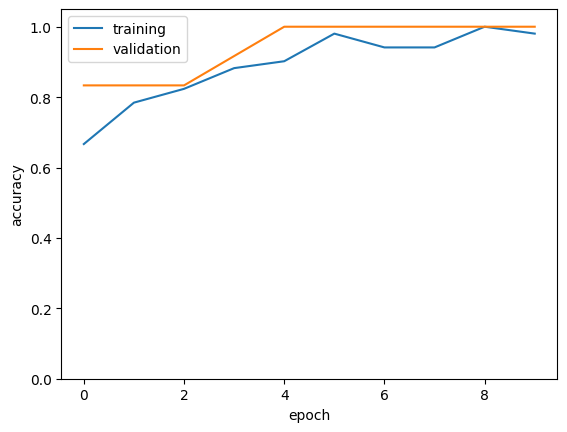

Validation accuracy: 1.00  (random guessing: 0.50)


In [8]:
history = model.fit(train_dataset,
                    validation_data=validation_dataset,
                    epochs=epochs)

plt.plot(history.history['accuracy'], label='training')
plt.plot(history.history['val_accuracy'], label='validation')
plt.xlabel('epoch'); plt.ylabel('accuracy'); plt.ylim(0, 1.05); plt.legend()
plt.show()
print(f"Validation accuracy: {history.history['val_accuracy'][-1]:.2f}  (random guessing: {1 / len(class_names):.2f})")

## Prediction

> **Video notes: stump the model**
> - Green, bumpy pumpkin → **60% squash** (fooled it)
> - White pumpkins → **50%** (coin flip)
> - Spaghetti squash with sauce → 65% pumpkin (mistake)
> - Surprise: the model relies mostly on **color**

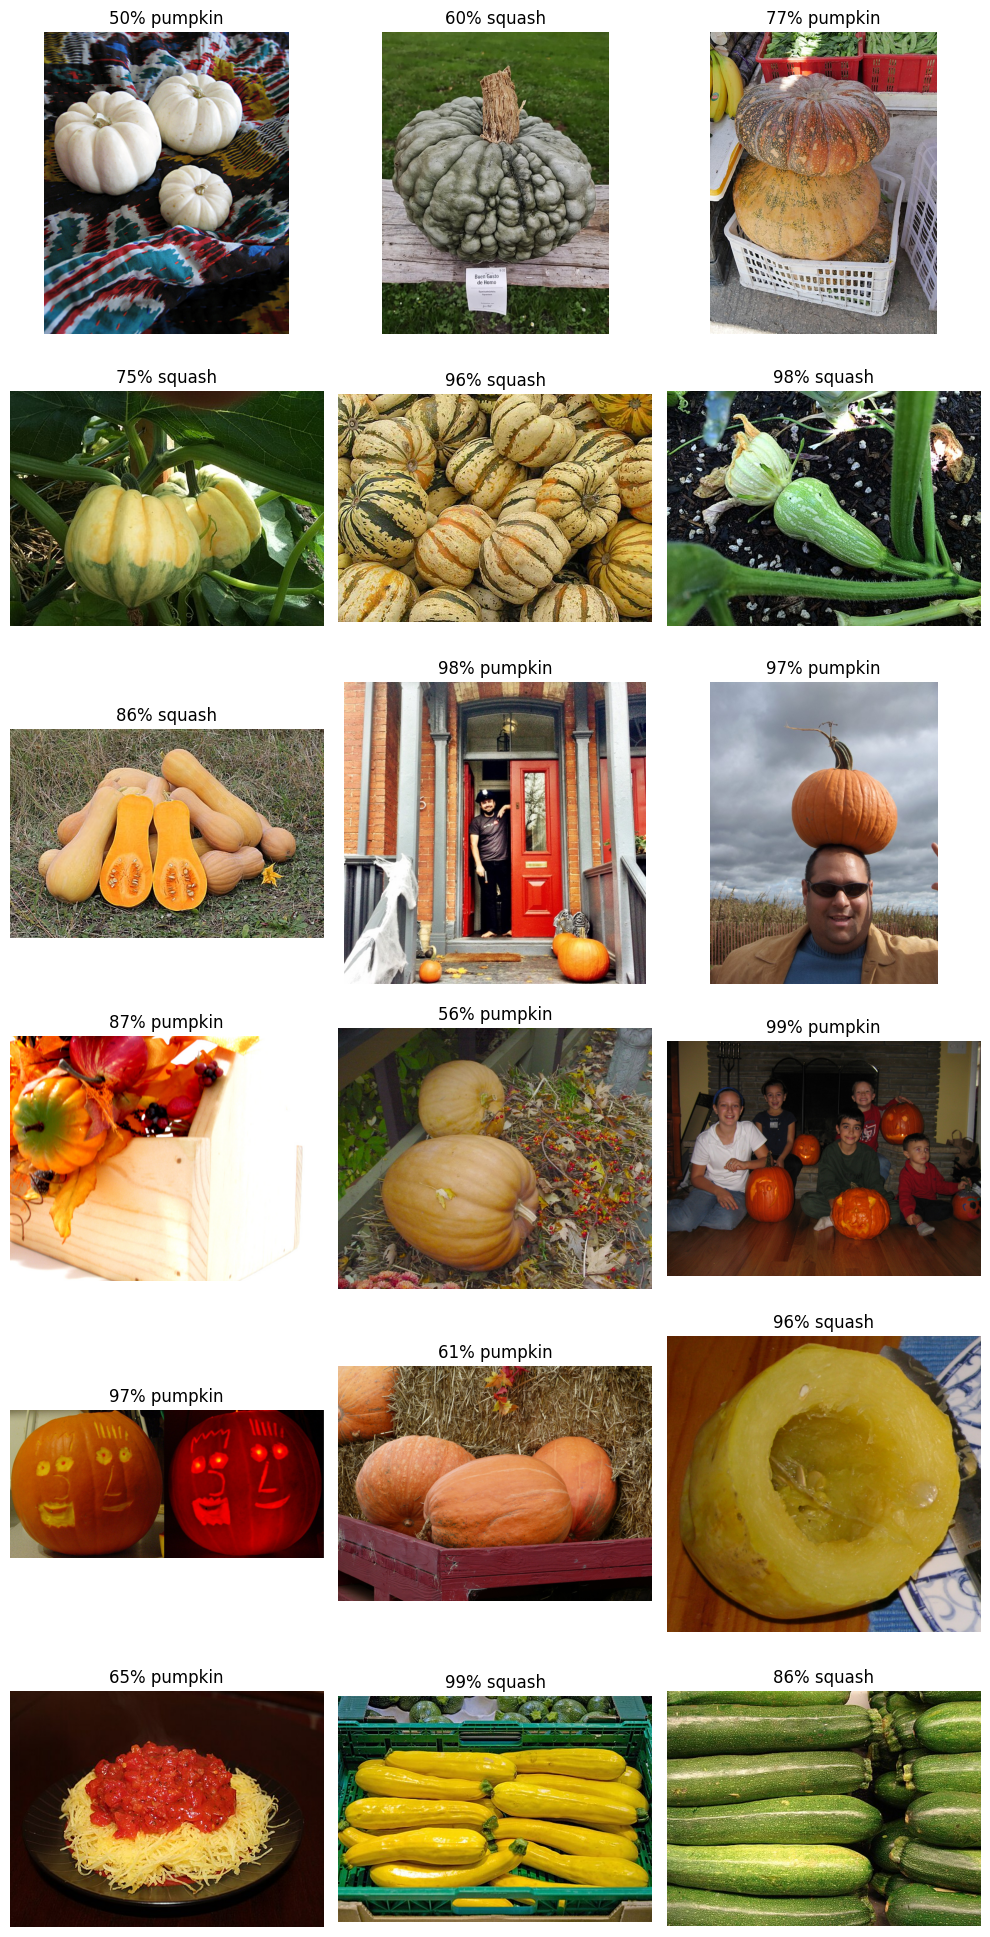

In [9]:
import os
from PIL import Image

IMG_EXT = ('.png', '.jpg', '.jpeg', '.jfif', '.webp', '.bmp')
onlyfiles = sorted(f for f in os.listdir(test_dir) if f.lower().endswith(IMG_EXT))   # skip hidden files and folders
n_rows = (len(onlyfiles) + 2) // 3
plt.figure(figsize=(10, 3.3 * n_rows))
for i, name in enumerate(onlyfiles):
    ax = plt.subplot(n_rows, 3, i + 1)
    img = Image.open(os.path.join(test_dir, name)).convert('RGB')
    img_array = tf.keras.utils.img_to_array(img.resize(IMG_SIZE))
    img_array = tf.expand_dims(img_array, 0)   # create a batch of one image
    predictions = model.predict(img_array, verbose=0)
    score = tf.nn.softmax(predictions[0])
    plt.imshow(img)
    plt.title(f"{100 * np.max(score):.0f}% {class_names[np.argmax(score)]}")
    plt.axis("off")
plt.tight_layout()
plt.show()

## Answers

**1. The two parts.** The model has **2,260,546** parameters in total, but only **2,562** are trainable. All 2,562 are in **Part 2**, the new Dense layer that classifies: 1,280 features × 2 categories + 2 biases = 2,562. The other 2,257,984 parameters are in **Part 1**, the frozen MobileNetV2 base. MobileNetV2 already learned general visual features (edges, curves, textures, ridges, colors) from 1.2 million ImageNet photos. Our ~30 images per category only have to teach the small final layer which of those features mean pumpkin and which mean squash. Learning 2,562 numbers needs far fewer examples than learning 2.26 million from scratch.

**2. Your accuracy.** The final validation accuracy is **1.00 (100%)**, compared with **50%** for random guessing with 2 categories. I don't see overfitting. Validation accuracy stays at or above training accuracy the whole time: it reaches 100% at epoch 5 and stays there, and the validation loss keeps falling (0.31 → 0.07). Training accuracy ends at 98%, slightly lower, because dropout and the random flips and rotations are only applied during training. One caveat: the validation set is only 12 images, so 100% means 12 out of 12. With more validation images, the accuracy would probably come out somewhat lower.

**3. A mistake.** The model called a plate of **cooked spaghetti squash with tomato sauce 65% pumpkin**, even though it is squash. Almost all of my squash training images show whole or halved raw squash. This one shows shredded yellow strands on a plate, covered in red-orange sauce. The large orange-red area and round plate shape look more like an orange pumpkin than any squash the model has seen, so it guessed pumpkin, but only with low confidence.

**4. Stump the model.** The **green, warty pumpkin** (stump2) fooled the model: it said **60% squash**. It worked because the model learned that pumpkins are orange and smooth, while many of my squash training images (acorn, zucchini) are green and darker. This pumpkin is gray-green and bumpy, so color and texture pointed toward squash. The **white pumpkins** (stump1) came very close too, at exactly **50% pumpkin**: a coin flip, because white is not a color the model saw for either category. Both results suggest the model relies heavily on color rather than shape.
